# Mixed turbulence: KT baseline

Use Pencil's readers and Matplotlib, following the school notebook workflow. This analysis needs only the small diagnostic, spectrum, and metadata files copied from Vera.

The pilot is a periodic, nonmagnetic relativistic radiation fluid on a 64³ grid. It starts with a random momentum field requesting a 50/50 compressional–vortical mixture. The actual physical-velocity split has not yet been measured.

This run provides **total physical-velocity spectra**, not separate compressional and vortical spectra. It also does not yet show where shocks form. Changes in energy or vorticity cannot be attributed to KT alone: pressure work, explicit viscosity/diffusion, and numerical effects all matter.

In [1]:
from pathlib import Path
import sys
import warnings

sys.path.insert(0, str(Path.home() / "Work/research/software/pencil-code/python"))
import pencil as pc
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / ".git").exists() and (p / "runs").is_dir())
run = root / "runs/mixed-turbulence-kt"
datadir = str(run / "data")

## Read the saved outputs

Read time-series numbers as double precision to retain their printed digits. This simulation has a cubic box and equal resolution in all directions; that is enough for Pencil to identify the spectrum bins without copying the processor grid files. The omitted grid-file warning is suppressed only after checking those assumptions.

The output intervals do not necessarily put a record exactly at the simulation's stopping time. We print the times actually present in the files.

In [2]:
ts = pc.read.ts(datadir=datadir, precision="d", quiet=True)
par = pc.read.param(datadir=datadir, quiet=True)
dim = pc.read.dim(datadir=datadir)
assert dim.nxgrid == dim.nygrid == dim.nzgrid
np.testing.assert_allclose(par.lxyz, np.repeat(par.lxyz[0], 3))
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=r"grid.dat not found. Assuming the box is cubical.")
    pw = pc.read.power(datadir=datadir, file_name="powerv.dat", quiet=True)

# The first bin is k=0. Fundamental wavenumber is 2*pi / box length.
k = np.arange(pw.v.shape[1]) * 2*np.pi / par.lxyz[0]
assert pw.v.shape == (len(pw.t), dim.nxgrid // 2)
assert np.isfinite(pw.v).all() and np.all(pw.v >= 0)
for name in ["t", "urms", "umax", "ekin", "rhom", "o2m", "divu2m"]:
    assert np.isfinite(getattr(ts, name)).all(), name
print(f"Time series: {len(ts.t)} records, t = {ts.t[0]:.6g} to {ts.t[-1]:.6g}")
print(f"Spectra: {len(pw.t)} records, t = {pw.t[0]:.6g} to {pw.t[-1]:.6g}")
print(f"Initial RMS velocity: {ts.urms[0]:.4f} c; initial maximum: {ts.umax[0]:.4f} c")

# The saved t=0 physical-velocity spectrum is all zeros. Exclude empty records.
nonempty = np.any(np.asarray(pw.v) > 0, axis=1)
spectrum_t = pw.t[nonempty]
velocity_power = np.asarray(pw.v)[nonempty]
assert len(spectrum_t) >= 2
print(f"Excluded {np.count_nonzero(~nonempty)} empty spectrum record(s).")
print(f"First usable spectrum: t = {spectrum_t[0]:.6g}")

Time series: 18 records, t = 0 to 9.68172
Spectra: 41 records, t = 0 to 9.76419
Initial RMS velocity: 0.1118 c; initial maximum: 0.3357 c
Excluded 1 empty spectrum record(s).
First usable spectrum: t = 0.0106816


## Time histories

- RMS and maximum speed track the flow strength.
- `ekin` is the relativistic kinetic-energy diagnostic.
- `o2m` is mean squared physical vorticity; `divu2m` is mean squared velocity divergence. These are gradient measures, not compressional/vortical energy fractions, and divergence squared does not distinguish compression from expansion.
- For this nonmagnetic radiation fluid, `ekin + rhom` is the corresponding mean lab-frame energy. Its fractional change is shown separately. Rounded text output limits the precision of this sum.

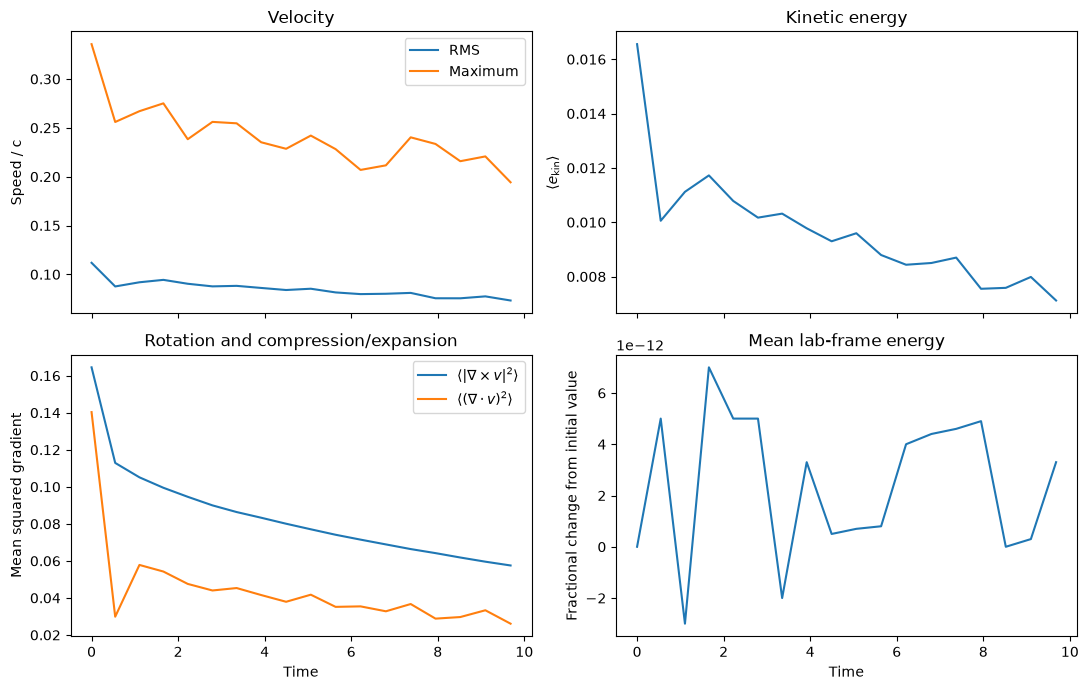

In [3]:
fig_history, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
axes[0, 0].plot(ts.t, ts.urms, label="RMS")
axes[0, 0].plot(ts.t, ts.umax, label="Maximum")
axes[0, 0].set_ylabel("Speed / c")
axes[0, 0].legend()
axes[0, 0].set_title("Velocity")
axes[0, 1].plot(ts.t, ts.ekin)
axes[0, 1].set_ylabel(r"$\langle e_{\rm kin}\rangle$")
axes[0, 1].set_title("Kinetic energy")
axes[1, 0].plot(ts.t, ts.o2m, label=r"$\langle|\nabla\times v|^2\rangle$")
axes[1, 0].plot(ts.t, ts.divu2m, label=r"$\langle(\nabla\cdot v)^2\rangle$")
axes[1, 0].set_ylabel("Mean squared gradient")
axes[1, 0].set_title("Rotation and compression/expansion")
axes[1, 0].legend()
energy = ts.ekin + ts.rhom
axes[1, 1].plot(ts.t, (energy - energy[0]) / energy[0])
axes[1, 1].set_ylabel("Fractional change from initial value")
axes[1, 1].set_title("Mean lab-frame energy")
for ax in axes[-1]:
    ax.set_xlabel("Time")
fig_history.tight_layout()
plt.show()

## Physical velocity spectrum versus wavenumber

Each shell sums the Fourier power of **physical velocity**. Pencil includes a factor of 1/2 in this spectrum. This is a velocity-power spectrum, not the relativistic kinetic-energy spectrum.

Small k corresponds to large structures; large k corresponds to finer structures. The zero mode is omitted from logarithmic axes. The reported spectrum covers spherical shells inside the grid cutoff; 64³ is a pilot resolution, not a converged turbulence reference.

The left plot overlays selected saved times. The right plot displays all saved spectra as a wavenumber–time heatmap. Neither plot separates compressional and vortical components.

The saved t=0 physical-velocity spectrum contains only zeros. It is excluded from these figures. The earliest usable spectrum is at t ≈ 0.0107, after the first timestep; this is not an exact initial-condition spectrum.

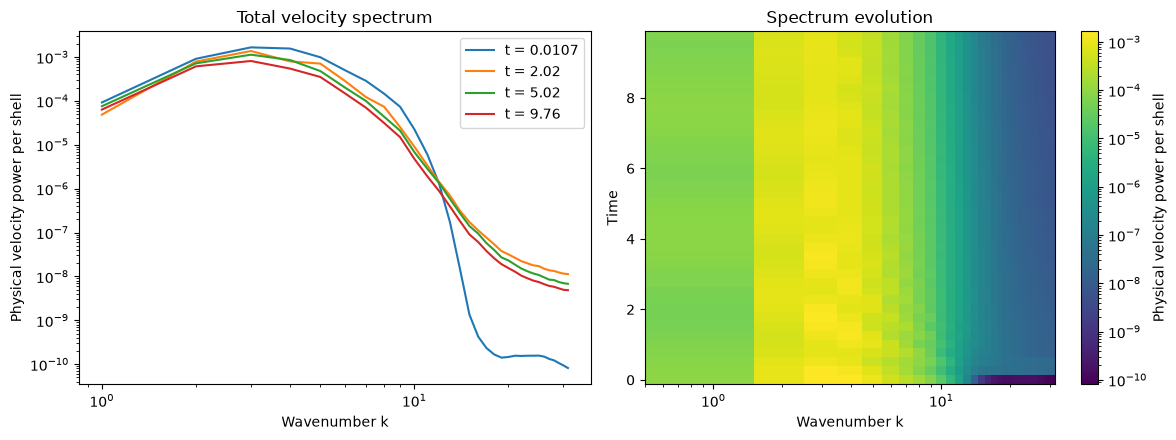

In [4]:
indices = sorted(set(np.argmin(np.abs(spectrum_t - t)) for t in [float(spectrum_t[0]), 2., 5., float(spectrum_t[-1])]))
positive_k = k > 0
spectra = np.asarray(velocity_power[:, positive_k])
fig_spectrum, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for i in indices:
    values = np.where(spectra[i] > 0, spectra[i], np.nan)
    axes[0].loglog(k[positive_k], values, label=f"t = {spectrum_t[i]:.3g}")
axes[0].set_xlabel("Wavenumber k")
axes[0].set_ylabel("Physical velocity power per shell")
axes[0].set_title("Total velocity spectrum")
axes[0].legend()
image = axes[1].pcolormesh(
    k[positive_k], spectrum_t, np.ma.masked_less_equal(spectra, 0),
    shading="nearest", norm=LogNorm(),
)
axes[1].set_xscale("log")
axes[1].set_xlabel("Wavenumber k")
axes[1].set_ylabel("Time")
axes[1].set_title("Spectrum evolution")
fig_spectrum.colorbar(image, ax=axes[1], label="Physical velocity power per shell")
fig_spectrum.tight_layout()
plt.show()

## Optional: save the figures

Save the figures to the ignored `plots` directory. The next analyses are spatial compression/vorticity maps and a Helmholtz split of the physical velocity. They require additional selected outputs or analysis on Vera; the total spectrum cannot be uniquely split after the vector field has been discarded.

In [5]:
out = run / "plots"
out.mkdir(exist_ok=True)
fig_history.savefig(out / "time_histories.png", dpi=200, bbox_inches="tight")
fig_spectrum.savefig(out / "velocity_spectra.png", dpi=200, bbox_inches="tight")
print("Saved figures in:", out)

Saved figures in: /Users/chrischoi/Work/grad/workshops/KAAI_alberto/KAAI_projects/runs/mixed-turbulence-kt/plots
